# 3. Choosing a pricing policy

**Concepts of:**

- how to turn simulations into a **decision table**;
- three classic ways to choose when you do not know your neighbour: the **average**, the **worst case** and the **regret**;
- how to check whether a recommendation survives a change in the assumptions.

This is the chapter where the model is used to **help someone decide**.

In [1]:
import axelrod as axl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bikes import *

city, tourist = season(CITY_WEEK), season(TOURIST_WEEK)

---
## 3.1 The renter's question

Imagine you are opening a bike rental shop next to an existing one. You must choose a pricing policy for the season, but you **do not know** how your neighbour sets prices.

You can still list the possibilities:

- your possible policies: `Steady`, `Opportunist`, `Reciprocal`, `DayAware`, `Mirror` (in variable `POLICIES`);
- your neighbour's possible policies: `Steady`, `Opportunist`, `Reciprocal`, `DayAware` (in variable `NEIGHBOURS`).

For each pair, a season gives your **mean revenue per day**.   
If we put all these numbers in a table: rows are your options, columns are the possible neighbours.  
This is a **decision table**. The function `decision_table` has build it with `play_season` function.

In [3]:
table_city = decision_table(POLICIES, NEIGHBOURS, city)
table_city

,Steady,Opportunist,Reciprocal,Day-aware
Steady,257.1,214.3,257.1,257.1
Opportunist,235.7,285.7,285.1,286.3
Reciprocal,257.1,285.4,257.1,285.4
Day-aware,221.4,285.2,285.1,300.0
Mirror,257.1,284.8,257.1,299.7


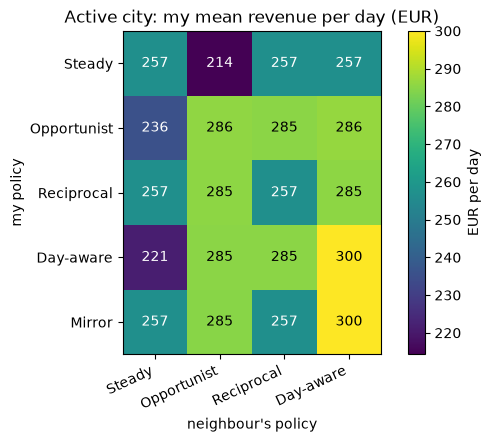

In [4]:
plot_table(table_city, title="Active city: my mean revenue per day (EUR)")
plt.show()

> **Reading.** Look at one column at a time: it tells you what to do **if** you knew your neighbour.
> - Against a `Steady` neighbour, surging alone on busy days is costly (bad reviews): `Opportunist` and `DayAware` earn less than the policies that keep the usual price.
> - Against a `DayAware` neighbour, who surges on busy days, the best is to surge as well (`DayAware` or `Mirror`).

No row is the best in every column: the right choice depends on the neighbour.

**Exercise 1**. 
- Build the decision table of the **tourist town** and 
- draw the two heatmaps side by side (`fig, axes = plt.subplots(1, 2, figsize=(14, 4))`, 
- then `plot_table(table, ax=ax, title=...)`). 
- Which policy is a very bad idea in the tourist town?

In [4]:
# Exercise 1: your code here

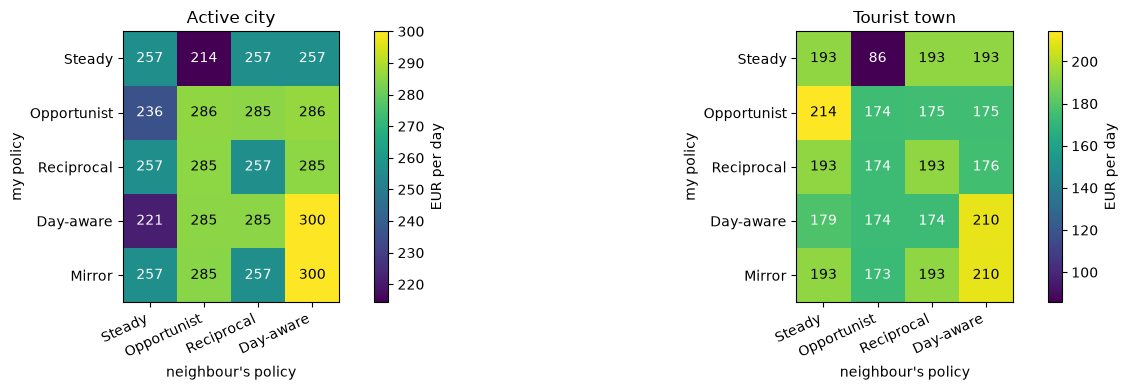

In [ ]:
plt.tight_layout(); plt.show()

In the tourist town, `Steady` against an `Opportunist` neighbour earns about 86 EUR per day: five quiet days a week, the neighbour undercuts and takes every customer. A renter who never reacts is an easy target where quiet days dominate.

---
## 3.2 Three ways to choose

When you do not know the column, you need a **criterion** to choose a row:

| Criterion | Question | Computation on the table |
|---|---|---|
| **average** (Laplace) | "all neighbours are equally likely" | mean of each row, take the largest |
| **worst case** (Wald, *maximin*) | "I want to be safe whatever happens" | minimum of each row, take the largest |
| **regret** (Savage, *minimax regret*) | "I do not want to regret my choice too much" | see exercise 3 |

**Exercise 2**. 
- For the two towns, build a small table with one row per policy and two columns: `"average"` (`table.mean(axis=1)`) and `"worst case"` (`table.min(axis=1)`). 
- Print it, together with the best policy for each criterion (`.idxmax()`).

In [6]:
# Exercise 2: your code here

Active city
policy        average  worst case
Steady          246.4       214.3
Opportunist     273.2       235.7
Reciprocal      271.2       257.1
Day-aware       272.9       221.4
Mirror          274.7       257.1
best average with: Mirror | best worst case with: Reciprocal 

Tourist town
policy        average  worst case
Steady          166.1        85.7
Opportunist     184.6       174.3
Reciprocal      183.8       173.7
Day-aware       184.0       173.7
Mirror          192.2       173.4
best average with: Mirror | best worst case with: Opportunist 



> **Reading.**
> - **Average**: `Mirror` comes first in both towns.
> - **Worst case**: in the active city, `Reciprocal` and `Mirror` tie (`idxmax` shows only the first one); in the tourist town, `Opportunist` comes first, but less than 1 EUR per day ahead of `Mirror`.

Always look at the numbers, not only at the winner: a difference of 1 EUR per day is far smaller than the uncertainty of our assumptions.

<hr style="width: 25%; margin-left: 0;">


**Exercise 3**. 
- The **regret** of a choice, against a given neighbour, is what you lose compared with the best choice you could have made against that neighbour:  `table.max() - table` (the maximum of each column, minus the table). 
- For each policy, compute 
  - its **largest regret** (maximum of each row), in both towns. 
- Which policy minimises its largest regret?

In [8]:
# Exercise 3: your code here

Active city -> largest regret: {'Steady': 71.4, 'Opportunist': 21.4, 'Reciprocal': 28.0, 'Day-aware': 35.7, 'Mirror': 28.0}
   smallest largest regret: Opportunist
Tourist town -> largest regret: {'Steady': 88.6, 'Opportunist': 35.2, 'Reciprocal': 34.5, 'Day-aware': 35.7, 'Mirror': 21.4}
   smallest largest regret: Mirror


> **Reading.** 
> - In the tourist town, `Mirror` has the smallest largest regret: whoever the neighbour is, it is never more than about 21 EUR per day away from the best answer. 
> - In the active city, `Opportunist` does slightly better on this criterion (21 against 28 for `Mirror`).
> Taken together, `Mirror` is chosen by most criteria and is never far from the best: it is a **robust** choice in this model.  
> `Opportunist` is a serious alternative in the active city, where busy days dominate.

---

## 3.3 Does the recommendation survive mistakes?

In a real shop, the price of the day is sometimes wrong: a seasonal employee forgets to update the sign, a promotion is posted on the wrong day.   
With `noise=0.05`, each renter's move is flipped on 5 % of the days.

**Exercise 4**. 
- For the tourist town, compute the decision table with `noise=0.05, seed=1`. 
- Then draw a bar chart comparing, for each policy, the **average** revenue without mistakes and with mistakes. 
- Is `Mirror` still the best choice on average?

In [10]:
# Exercise 4: your code here

policy        no mistakes  5 % mistakes
Steady              166.1         162.5
Opportunist         184.6         183.8
Reciprocal          183.8         174.5
Day-aware           184.0         173.1
Mirror              192.2         174.2


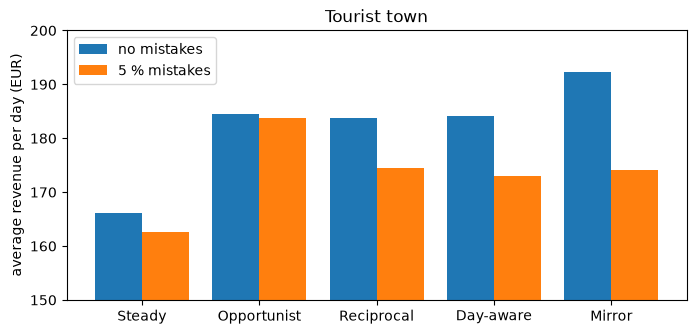

In [ ]:

#TODO: define no_mistakes = average revenue per day, without errors, for each policy in POLICIES
#TODO: define with_mistakes =  average revenue per day, with 5% errors, for each policy in POLICIES


x = np.arange(len(policies))                              # one position per policy
width = 0.4                                               # width of each bar
plt.figure(figsize=(8, 3.5))
plt.bar(x - width / 2, no_mistakes,   width, label="no mistakes")
plt.bar(x + width / 2, with_mistakes, width, label="5 % mistakes")
plt.xticks(x, policies)
plt.ylabel("average revenue per day (EUR)"); plt.ylim(150, 200); plt.title("Tourist town")
plt.legend(); plt.show()

> **Reading.** 
> - With mistakes, the reciprocal policies (`Reciprocal`, `DayAware`, `Mirror`) lose about 9 to 18 EUR per day, while `Opportunist` and `Steady` barely change. 
> - A single wrong price triggers a reaction from the neighbour, which triggers a reaction in return: the **echo** effect of the iterated prisoner's dilemma. 
> - `Opportunist`, which never reacts to anything, is not affected by the echo, and becomes the best choice on average.

The recommendation therefore depends on an assumption that is easy to overlook: **how reliable are the posted prices?**

---

## What would we tell a renter?

Based on this (simple) model:

1. **Never be a pushover on quiet days.** A renter who never reacts to undercutting loses most of the weekday revenue in a tourist town.
2. **Do not surge alone.** A high price that the shop next door does not follow costs more in reputation than it brings in.
3. **Read your neighbour day type by day type.** A surge on a busy day is not an attack; reacting to it with a price cut starts a pointless war.
4. **If your prices are reliable, follow your neighbour (`Mirror`).** It is the most robust policy across towns and criteria.
5. **If mistakes are frequent, reactive policies suffer.** Then either make prices reliable, or use a policy that forgives occasional mistakes (for instance a `Mirror` that waits for **two** undercuts in a row before reacting: write it and check it with the decision table).
